<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%206/MRayhanZamzami_JS06_ANN_P2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 2 - Approximate Nearest Neighbors (ANN) dengan FAISS


In [1]:
# Instalasi FAISS CPU jika dijalankan di Google Colab
!pip install faiss-cpu

### 1. Implementasi FAISS IndexFlatL2 vs IndexIVFPQ (Dataset 2D - 1.000 Titik)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.0001590251922607422 detik
Waktu IVF+PQ: 0.00028133392333984375 detik


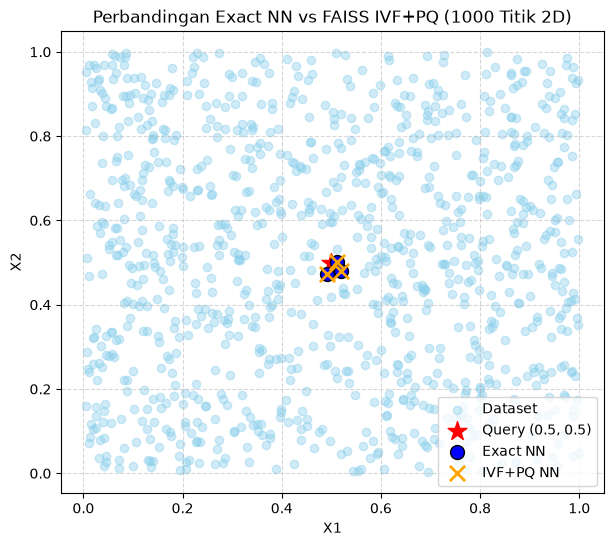

In [2]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat, "detik")
print("Waktu IVF+PQ:", time_ivfpq, "detik")

# 5. Visualisasi
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Dataset", c="skyblue")
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label="Query (0.5, 0.5)")

# Tetangga dari Flat
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='orange', marker='x', s=120, linewidth=2, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ (1000 Titik 2D)")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 2. Eksperimen Variasi Parameter (Tugas Modul)



In [3]:
import pandas as pd

def benchmark_faiss(n_samples, dim, metric_type='L2'):
    np.random.seed(42)
    X_data = np.random.rand(n_samples, dim).astype('float32')
    q_data = np.random.rand(1, dim).astype('float32')
    
    if metric_type == 'IP':
        # Normalisasi vektor untuk Cosine Similarity via Inner Product
        faiss.normalize_L2(X_data)
        faiss.normalize_L2(q_data)
        metric = faiss.METRIC_INNER_PRODUCT
        quantizer = faiss.IndexFlatIP(dim)
        index_exact = faiss.IndexFlatIP(dim)
    else:
        metric = faiss.METRIC_L2
        quantizer = faiss.IndexFlatL2(dim)
        index_exact = faiss.IndexFlatL2(dim)
    
    # 1. Exact Search (Flat)
    t0 = time.time()
    index_exact.add(X_data)
    build_time_exact = time.time() - t0
    
    t0 = time.time()
    D_ex, I_ex = index_exact.search(q_data, 5)
    search_time_exact = time.time() - t0
    
    # 2. IVF-Flat Index (Approximate yang fleksibel untuk berbagai ukuran & dimensi)
    nlist = min(100, max(10, int(np.sqrt(n_samples))))
    index_ivf = faiss.IndexIVFFlat(quantizer, dim, nlist, metric)
    
    t0 = time.time()
    index_ivf.train(X_data)
    index_ivf.add(X_data)
    build_time_ivf = time.time() - t0
    
    index_ivf.nprobe = min(10, nlist)
    t0 = time.time()
    D_ivf, I_ivf = index_ivf.search(q_data, 5)
    search_time_ivf = time.time() - t0
    
    # Hitung Recall@5 terhadap Exact NN
    recall = len(set(I_ex[0]) & set(I_ivf[0])) / 5.0
    
    return {
        "Jumlah Data": f"{n_samples:,}",
        "Dimensi": f"{dim}D",
        "Metric": metric_type,
        "Build Exact (s)": f"{build_time_exact:.5f}",
        "Search Exact (ms)": f"{search_time_exact*1000:.3f}",
        "Build IVF (s)": f"{build_time_ivf:.5f}",
        "Search IVF (ms)": f"{search_time_ivf*1000:.3f}",
        "Recall@5": f"{recall:.2f}"
    }

configs = [
    (1000, 2, 'L2'),
    (1000, 2, 'IP'),
    (1000, 5, 'L2'),
    (1000, 5, 'IP'),
    (100000, 2, 'L2'),
    (100000, 2, 'IP'),
    (100000, 5, 'L2'),
    (100000, 5, 'IP'),
]

results = [benchmark_faiss(n, d, m) for n, d, m in configs]
df_res = pd.DataFrame(results)
display(df_res)

,Jumlah Data,Dimensi,Metric,Build Exact (s),Search Exact (ms),Build IVF (s),Search IVF (ms),Recall@5
0,"1,000",2D,L2,0.00002,0.118,0.00338,0.815,1.00
1,"1,000",2D,IP,0.00002,0.616,0.00312,0.048,1.00
2,"1,000",5D,L2,0.00002,0.139,0.00442,0.051,1.00
3,"1,000",5D,IP,0.00002,0.067,0.00416,0.065,1.00
4,"100,000",2D,L2,0.00048,0.365,0.09153,0.182,1.00
5,"100,000",2D,IP,0.00049,0.164,0.07979,0.128,0.60
6,"100,000",5D,L2,0.00128,1.087,0.20205,0.199,1.00
7,"100,000",5D,IP,0.00121,0.224,0.13149,0.221,1.00
